# Laboratory Exercise 2: Online Orders

Basket is an online shop that delivers across Macedonia and takes orders on its website, in its mobile app, and through a marketplace. Its export in `data/orders.csv` holds one row per order, and `data/new-orders.csv` counts the orders placed on each day. The orders are synthetic and describe no real customer, shop, or marketplace.

The columns of `orders.csv` are these:

- `order_id`, the identifier of the order, and `ordered_on`, the day it was placed,
- `city`, the city of delivery, and `sales_channel`, which is the website, the mobile app, or the marketplace,
- `customer_type`, a consumer or a business, and `items`, the number of items as the order system recorded it,
- `membership`, the customer's loyalty level, one of none, bronze, silver, gold, and platinum,
- `payment_method`, and `delivery`, which is home, a parcel locker, or store pickup, with `delivery_fee`, the fee in euros,
- `package_weight`, the weight of the package in kilograms, `order_value`, the value of the goods in euros, and `delivery_days`, the days until the order arrived,
- `discount`, the discount in euros, and `account_age_days`, the days since the customer opened the account, and
- `rating`, the customer's rating of the order from 1 to 5, which a later model will predict.

The orders are to be prepared for that model: every gap filled for a reason, every unusual value understood, every label turned into numbers, and every column brought to a comparable scale, with every step learned from the training orders alone. No request asks for a model.

Answer each request in the cells below it, and add as many cells as you need. The laboratory test asks for values and decisions that your notebook computes, so keep every result visible, run the notebook from top to bottom before you submit it, and make sure it runs on a machine without internet access.

## Setup

The cells in this section are written already. Run them before the tasks.

In [37]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from scipy import stats
from sklearn.base import BaseEstimator, TransformerMixin, clone
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import IsolationForest
from sklearn.experimental import enable_iterative_imputer  # noqa: F401
from sklearn.impute import IterativeImputer, KNNImputer, MissingIndicator, SimpleImputer
from sklearn.model_selection import train_test_split
from sklearn.neighbors import LocalOutlierFactor
from sklearn.pipeline import Pipeline, make_pipeline
from sklearn.preprocessing import (MinMaxScaler, OneHotEncoder, OrdinalEncoder, PowerTransformer, RobustScaler,
                                   StandardScaler)

DATA = Path("data")
# Every random step uses this seed, so a rerun gives the same result.
SEED = 2026

In [38]:
# The course style.
PALETTE = ["#0072B2", "#D55E00", "#009E73", "#CC79A7", "#E69F00", "#56B4E9", "#1e2a24"]
GROUND, INK, GRID = "#ffffff", "#1e2a24", "#e2e6e4"
plt.rcParams.update(
    {
        "figure.figsize": (8, 4.5),
        "figure.facecolor": GROUND,
        "figure.constrained_layout.use": True,
        "savefig.facecolor": GROUND,
        "savefig.transparent": False,
        "font.family": "sans-serif",
        "font.sans-serif": ["Archivo", "DejaVu Sans"],
        "font.size": 12,
        "text.color": INK,
        "axes.facecolor": GROUND,
        "axes.edgecolor": INK,
        "axes.labelcolor": INK,
        "axes.titleweight": "bold",
        "axes.titlelocation": "left",
        "axes.spines.top": False,
        "axes.spines.right": False,
        "axes.grid": True,
        "axes.axisbelow": True,
        "axes.prop_cycle": plt.cycler(color=PALETTE),
        "grid.color": GRID,
        "xtick.color": INK,
        "ytick.color": INK,
        "legend.frameon": False,
        "image.cmap": "cividis",
    }
)
sns.set_palette(PALETTE)

In [39]:
class FrequencyEncoder(TransformerMixin, BaseEstimator):
    """Replaces each category with its share of the rows passed to fit, and an unseen category with 0."""

    def fit(self, X: pd.DataFrame, y: object = None) -> "FrequencyEncoder":
        self.shares_ = {column: X[column].value_counts(normalize=True) for column in X.columns}
        return self

    def transform(self, X: pd.DataFrame) -> np.ndarray:
        return np.column_stack([X[column].map(share).fillna(0).to_numpy(dtype=float)
                                for column, share in self.shares_.items()])

    def get_feature_names_out(self, input_features: object = None) -> np.ndarray:
        return np.array([f"{column}_frequency" for column in self.shares_])

In [40]:
orders = pd.read_csv(DATA / "orders.csv")
new_orders = pd.read_csv(DATA / "new-orders.csv")
orders.head()

,order_id,ordered_on,city,customer_type,sales_channel,membership,payment_method,delivery,items,package_weight,order_value,delivery_days,delivery_fee,discount,account_age_days,rating
0,73001,2025-12-01,Skopje,consumer,marketplace,gold,?,home,5,?,144.72,4,2.9,4.4,370,4
1,73002,2025-12-02,Gostivar,consumer,website,bronze,card,home,6,6.0,87.73,1,2.8,9.4,200,5
2,73003,2025-12-04,Skopje,consumer,mobile app,none,wallet,home,3,2.5,40.13,4,3.8,1.2,60,3
3,73004,2025-12-05,Gostivar,consumer,marketplace,bronze,wallet,store pickup,1,0.6,20.97,5,?,0.0,195,5
4,73005,2025-12-05,Skopje,consumer,website,none,card,home,4,3.5,69.19,1,3.2,1.8,100,4


## Task 1: The Gaps

### 1.1 Reading the Gaps

The file writes a value it does not have with a marker of its own. Read the orders into a table named `df` in which every such value is missing. Count the missing values in each column, and show where they fall.

order_id             0
ordered_on           0
city                 0
customer_type        0
sales_channel        0
membership           0
payment_method      17
delivery             0
items                0
package_weight      78
order_value          0
delivery_days       23
delivery_fee        40
discount             0
account_age_days     0
rating               8
dtype: int64


<function matplotlib.pyplot.show(close=None, block=None)>

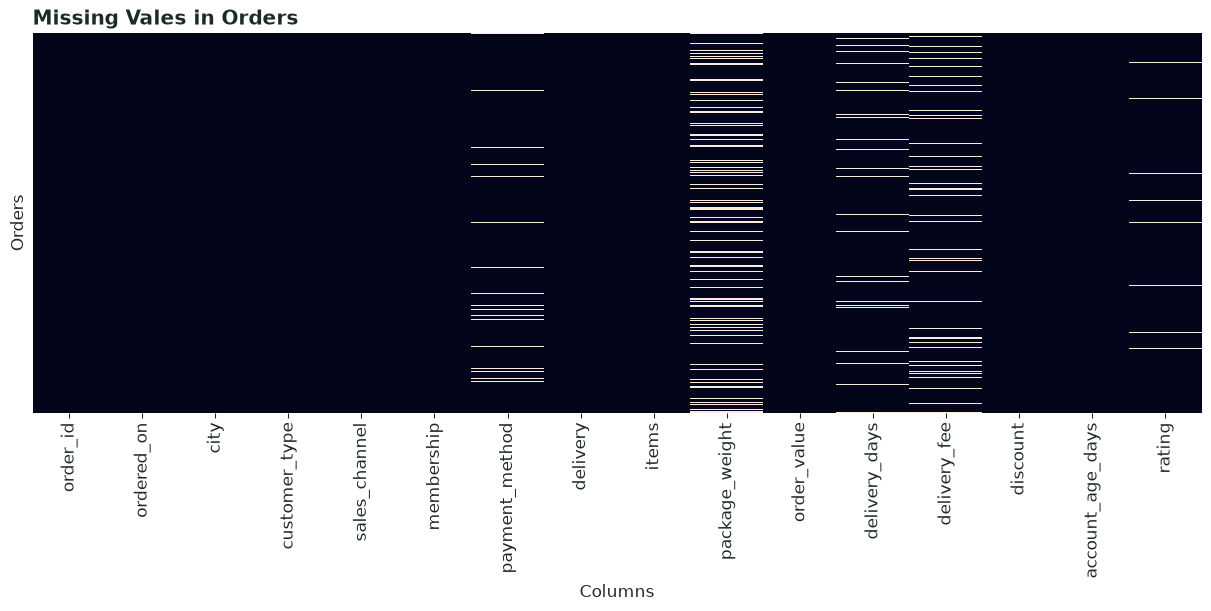

In [41]:
df = pd.read_csv(DATA / "orders.csv", na_values=["?"])

#broenje na nedostasuvachka vrednost
print(df.isna().sum())

#tochno kade nedostasuva
plt.figure(figsize=(12,6))
sns.heatmap(df.isna(), cbar=False, yticklabels=False)
plt.title("Missing Vales in Orders")
plt.xlabel("Columns")
plt.ylabel("Orders")
plt.show

### 1.2 Why Values Are Missing

For each column with missing values, find out whether its gaps depend on another column, whether a gap means that the value does not exist, or whether the gaps follow no pattern. Show the comparison that decides each case.

In [42]:

# Koloni so missing values
missing_cols = df.columns[df.isna().any()].tolist()

# Koloni po kategorii za sporedba
group_cols = [
    "delivery",
    "sales_channel",
    "customer_type",
    "membership",
    "city"
]

for col in group_cols:
    print(f"\nMissing values by {col} (%)")

    result = df.groupby(col, dropna=False)[missing_cols].agg(
        lambda x: x.isna().mean() * 100
    ).round(1)

    result.insert(
        0, "total_orders",
        df.groupby(col, dropna=False).size()
    )

    display(result)



Missing values by delivery (%)


,total_orders,payment_method,package_weight,delivery_days,delivery_fee,rating
delivery,,,,,,
home,253,4.3,21.3,6.3,0.0,2.4
parcel locker,107,4.7,16.8,4.7,0.0,1.9
store pickup,40,2.5,15.0,5.0,100.0,0.0



Missing values by sales_channel (%)


,total_orders,payment_method,package_weight,delivery_days,delivery_fee,rating
sales_channel,,,,,,
marketplace,166,6.0,40.4,6.0,7.8,4.2
mobile app,95,3.2,2.1,4.2,11.6,0.0
website,139,2.9,6.5,6.5,11.5,0.7



Missing values by customer_type (%)


,total_orders,payment_method,package_weight,delivery_days,delivery_fee,rating
customer_type,,,,,,
business,14,7.1,0.0,7.1,28.6,0.0
consumer,386,4.1,20.2,5.7,9.3,2.1



Missing values by membership (%)


,total_orders,payment_method,package_weight,delivery_days,delivery_fee,rating
membership,,,,,,
bronze,118,3.4,22.0,4.2,12.7,3.4
gold,48,6.2,20.8,12.5,6.2,0.0
none,154,2.6,14.9,3.9,11.0,1.9
platinum,14,14.3,28.6,7.1,7.1,0.0
silver,66,6.1,22.7,7.6,6.1,1.5



Missing values by city (%)


,total_orders,payment_method,package_weight,delivery_days,delivery_fee,rating
city,,,,,,
Berovo,3,0.0,0.0,0.0,33.3,0.0
Bitola,22,4.5,40.9,4.5,9.1,4.5
Debar,3,0.0,33.3,0.0,0.0,0.0
Delčevo,3,0.0,33.3,0.0,0.0,0.0
Dojran,3,0.0,0.0,0.0,0.0,0.0
Gevgelija,3,0.0,66.7,0.0,0.0,0.0
Gostivar,16,6.2,31.2,0.0,25.0,0.0
Kavadarci,9,0.0,22.2,11.1,0.0,11.1
Kičevo,15,6.7,20.0,13.3,13.3,0.0


In [43]:

# Structural missingness: delivery_fee
print("Delivery fee by delivery type:")
display(
    pd.crosstab(
        df["delivery"],
        df["delivery_fee"].isna(),
        margins=True
    )
)

# Missing values depending on sales channel
for col in ["package_weight", "rating", "payment_method"]:
    print(f"\nMissing {col} by sales channel (%):")
    display(
        pd.crosstab(
            df["sales_channel"],
            df[col].isna(),
            normalize="index"
        ).mul(100).round(1)
    )

# Missing delivery days by delivery type
print("\nMissing delivery_days by delivery (%):")
display(
    pd.crosstab(
        df["delivery"],
        df["delivery_days"].isna(),
        normalize="index"
    ).mul(100).round(1)
)


Delivery fee by delivery type:


delivery_fee,False,True,All
delivery,,,
home,253,0,253
parcel locker,107,0,107
store pickup,0,40,40
All,360,40,400



Missing package_weight by sales channel (%):


package_weight,False,True
sales_channel,,
marketplace,59.6,40.4
mobile app,97.9,2.1
website,93.5,6.5



Missing rating by sales channel (%):


rating,False,True
sales_channel,,
marketplace,95.8,4.2
mobile app,100.0,0.0
website,99.3,0.7



Missing payment_method by sales channel (%):


payment_method,False,True
sales_channel,,
marketplace,94.0,6.0
mobile app,96.8,3.2
website,97.1,2.9



Missing delivery_days by delivery (%):


delivery_days,False,True
delivery,,
home,93.7,6.3
parcel locker,95.3,4.7
store pickup,95.0,5.0


### 1.3 What Deleting Would Cost

Find out how many orders would remain if every order with a missing value were dropped, and how the mix of sales channels would change. Then decide what to do with the orders that state no rating, and apply the decision to `df`.

In [44]:

# Vkupen broj naracki pred brisenje
total_before = len(df)

# Probno brisenje na site redovi so missing values
df_complete = df.dropna()

# Broj naracki po brisenje
total_after = len(df_complete)

# Kolku naracki bi izgubile
lost_orders = total_before - total_after

print("Orders before:", total_before)
print("Orders after:", total_after)
print("Orders lost:", lost_orders)
print("Percentage lost:", round(lost_orders / total_before * 100, 2), "%")


Orders before: 400
Orders after: 254
Orders lost: 146
Percentage lost: 36.5 %


In [45]:

before = df["sales_channel"].value_counts(normalize=True) * 100
after = df_complete["sales_channel"].value_counts(normalize=True) * 100

comparison = pd.DataFrame({
    "Before (%)": before,
    "After (%)": after
})

comparison["Change (pp)"] = (
    comparison["After (%)"] - comparison["Before (%)"]
)

display(comparison.round(2))


,Before (%),After (%),Change (pp)
sales_channel,,,
marketplace,41.50,29.92,-11.58
mobile app,23.75,30.31,6.56
website,34.75,39.76,5.01


In [46]:

# Brishenje samo na redovi so missing rating
df = df.dropna(subset=["rating"]).copy()

print("Remaining orders:", len(df))
print("Missing ratings:", df["rating"].isna().sum())


Remaining orders: 392
Missing ratings: 0


## Task 2: The Split and the Fills

### 2.1 The Test Orders

The orders placed on 1 September 2026 or later stand in for orders that the preparation has never seen. Set them aside as the test orders, `X_test` and `y_test`, and keep the earlier orders as the training orders, `X_train` and `y_train`, where `X` holds every column except the rating and `y` holds the rating. Every later step learns only from the training orders. Report the number of each.

In [47]:
# pretvoranje na datumot vo datetime
df["ordered_on"] = pd.to_datetime(df["ordered_on"])

#datum za podelba
cutoff = pd.Timestamp("2026-09-01")

#podelba na train i set spored datum
train = df[df["ordered_on"] < cutoff].copy()
test = df[df["ordered_on"] >= cutoff].copy()

In [48]:
# training data
X_train = train.drop(columns=["rating"])
y_train= train["rating"]

#testing data
X_test = test.drop(columns=["rating"])
y_test = test["rating"]

print("Training orders:", len(X_train))
print("Testing orders:", len(X_test))
print("Total orders:", len(X_train) + len(X_test))


Training orders: 294
Testing orders: 98
Total orders: 392




Податоците се поделени според датумот **1 септември 2026 година**.

- **Training set:** 294 нарачки (75%).
- **Test set:** 98 нарачки (25%).

Колоната `rating` е целната променлива (`y`), додека сите останати колони се влезни податоци (`X`).

Сите понатамошни чекори за подготовка ќе се учат исклучиво од тренинг-податоците за да се спречи **Data Leakage**.


### 2.2 Filling the Gaps

Fill the gaps of each column in the way its pattern calls for, learning every fill from the training orders, and keep a record of the filled values wherever the absence itself carries information. Report the value that each fill by a single value uses.

In [49]:
# najchest payment metod (moda)
payment_mode = X_train["payment_method"].mode()[0]

#mediana za delivery_days
days_median = X_train["delivery_days"].median()

#mediana za package_withgt po sales_channel
weight_medians = X_train.groupby("sales_channel")["package_weight"].median()

# globalna mediana za rezervna vrednost
weight_global_median = X_train["package_weight"].median()

print("Payment method mode:", payment_mode)
print("Delivery days median:", days_median)
print("Delivery fee for store pickup:", 0)

print("\nPackage weight medians by sales channel:")
print(weight_medians)

print("\nGlobal package weight median:", weight_global_median)


Payment method mode: card
Delivery days median: 3.0
Delivery fee for store pickup: 0

Package weight medians by sales channel:
sales_channel
marketplace    2.0
mobile app     2.4
website        2.3
Name: package_weight, dtype: float64

Global package weight median: 2.25


In [50]:

# prajme kopii
X_train = X_train.copy()
X_test = X_test.copy()

for data in [X_train, X_test]:

    # Missing indicators (1 = nedostasuva, 0 = postoi)
    data["package_weight_missing"] = data["package_weight"].isna().astype(int)
    data["delivery_fee_missing"] = data["delivery_fee"].isna().astype(int)

    # Payment method - moda
    data["payment_method"] = data["payment_method"].fillna(payment_mode)

    # Delivery days - mediana
    data["delivery_days"] = data["delivery_days"].fillna(days_median)

    # Package weight - mediana po sales channel
    group_values = data["sales_channel"].map(weight_medians)

    data["package_weight"] = (
        data["package_weight"]
        .fillna(group_values)
        .fillna(weight_global_median)
    )

    # Delivery fee - 0 za store pickup
    pickup_missing = (
        (data["delivery"] == "store pickup") &
        (data["delivery_fee"].isna())
    )

    data.loc[pickup_missing, "delivery_fee"] = 0

# Proverka na missing values
print("Missing values in X_train:")
print(X_train.isna().sum())

print("\nMissing values in X_test:")
print(X_test.isna().sum())


Missing values in X_train:
order_id                  0
ordered_on                0
city                      0
customer_type             0
sales_channel             0
membership                0
payment_method            0
delivery                  0
items                     0
package_weight            0
order_value               0
delivery_days             0
delivery_fee              0
discount                  0
account_age_days          0
package_weight_missing    0
delivery_fee_missing      0
dtype: int64

Missing values in X_test:
order_id                  0
ordered_on                0
city                      0
customer_type             0
sales_channel             0
membership                0
payment_method            0
delivery                  0
items                     0
package_weight            0
order_value               0
delivery_days             0
delivery_fee              0
discount                  0
account_age_days          0
package_weight_missing    0
delivery_


zakluchok

Недостасувачките вредности се пополнети со соодветни методи, користејќи вредности пресметани само од тренинг-податоците.

- **payment_method:** Најчеста вредност (Mode) – `card`.
- **delivery_days:** Медијана – `3.0` дена.
- **package_weight:** Медијана според продажниот канал:
  - marketplace – `2.0` kg
  - mobile app – `2.4` kg
  - website – `2.3` kg
  - глобална медијана (резерва) – `2.25` kg.
- **delivery_fee:** `0` евра за `store pickup`, под претпоставка дека нема наплата за достава.

Додадени се две нови колони (`package_weight_missing` и `delivery_fee_missing`) за да се зачува информацијата за првично недостасувачките вредности.

По обработката, `X_train` и `X_test` немаат недостасувачки вредности.

Сите статистички вредности се пресметани исклучиво од `X_train`, со што се избегнува **Data Leakage**.


### 2.3 How Well a Fill Recovers the Weight

Hide the known package weight of every training order whose identifier is divisible by five. Fill these weights back in three ways, all from the numeric columns: with the median weight, from the five most similar orders judged on standardized columns, and by predicting each column from the others in rounds with the seed 2026. Measure how far each fill lies from the true weights on average, and show the filled weights against the true ones.

In [51]:

# Gi zemame samo numerickite koloni od originalniot train
numeric = train.select_dtypes(include=np.number).drop(
    columns=["order_id", "rating"], errors="ignore"
).copy()

# Gi naogjame ID broevite delivi so 5
ids = pd.to_numeric(train["order_id"])


# skrij gi tezhinite koi orginalno postojat
mask = (ids % 5 == 0) & numeric["package_weight"].notna()

# Gi zacuvuvame vistinskite tezini
true_weights = numeric.loc[mask, "package_weight"].copy()


#prajme kopija i gi sokrivame izbranite tezhini
masked_numeric = numeric.copy()
masked_numeric.loc[mask, "package_weight"] = np.nan

print("Hidden weights:", mask.sum())
print("Original missing weights:", numeric["package_weight"].isna().sum())
print("Missing weights after hiding:", masked_numeric["package_weight"].isna().sum())


Hidden weights: 45
Original missing weights: 56
Missing weights after hiding: 101


In [52]:

# 1. MEDIAN IMPUTATION
median_imputer = SimpleImputer(strategy="median")

median_filled = pd.DataFrame(
    median_imputer.fit_transform(masked_numeric),
    columns=masked_numeric.columns,
    index=masked_numeric.index
)

# 2. KNN IMPUTATION (5 neighbors)
scaler = StandardScaler()
scaled_data = scaler.fit_transform(masked_numeric)

knn_imputer = KNNImputer(n_neighbors=5)
knn_scaled = knn_imputer.fit_transform(scaled_data)

knn_filled = pd.DataFrame(
    scaler.inverse_transform(knn_scaled),
    columns=masked_numeric.columns,
    index=masked_numeric.index
)

# 3. ITERATIVE IMPUTATION
iterative_imputer = IterativeImputer(
    random_state=SEED,
    max_iter=15
)

iterative_filled = pd.DataFrame(
    iterative_imputer.fit_transform(masked_numeric),
    columns=masked_numeric.columns,
    index=masked_numeric.index
)

# Gi zemame samo prethodno sokrienite tezini
predictions = pd.DataFrame({
    "True weight": true_weights,
    "Median": median_filled.loc[mask, "package_weight"],
    "KNN": knn_filled.loc[mask, "package_weight"],
    "Iterative": iterative_filled.loc[mask, "package_weight"]
})

display(predictions.head(10))


,True weight,Median,KNN,Iterative
4,3.5,2.1,2.04,3.291306
9,2.9,2.1,2.42,3.369984
14,35.0,2.1,40.18,27.305743
19,2.0,2.1,1.90,1.914790
29,4.7,2.1,2.80,6.816361
34,1.0,2.1,1.58,1.201118
39,2.1,2.1,4.02,2.351400
44,4.4,2.1,2.14,5.401174
54,0.9,2.1,2.54,1.754598
59,0.7,2.1,2.00,2.670151


In [53]:

# Presmetka na MAE za sekoj metod
mae_results = pd.DataFrame({
    "Method": ["Median", "KNN", "Iterative"],
    "MAE (kg)": [
        (predictions["True weight"] - predictions["Median"]).abs().mean(),
        (predictions["True weight"] - predictions["KNN"]).abs().mean(),
        (predictions["True weight"] - predictions["Iterative"]).abs().mean()
    ]
})

# Podreduvanje od najmala do najgolema greska
mae_results = mae_results.sort_values("MAE (kg)")

display(mae_results.round(3))


,Method,MAE (kg)
2,Iterative,1.160
1,KNN,1.576
0,Median,2.662


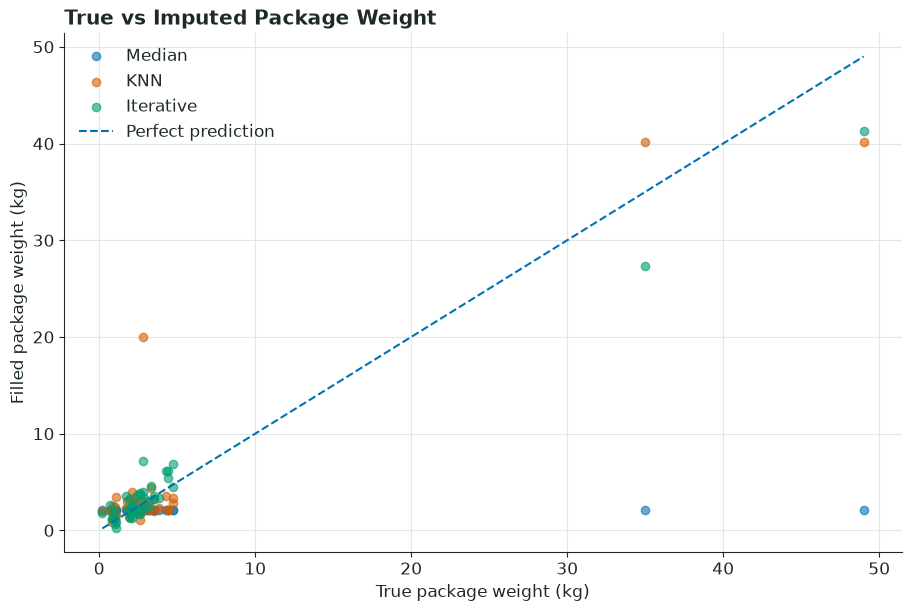

In [54]:

plt.figure(figsize=(9, 6))

for method in ["Median", "KNN", "Iterative"]:
    plt.scatter(
        predictions["True weight"],
        predictions[method],
        alpha=0.6,
        label=method
    )

# Idealna linija - tocno predviduvanje
all_values = predictions.to_numpy()
low = all_values.min()
high = all_values.max()

plt.plot([low, high], [low, high], "--", label="Perfect prediction")

plt.xlabel("True package weight (kg)")
plt.ylabel("Filled package weight (kg)")
plt.title("True vs Imputed Package Weight")
plt.legend()
plt.show()


### 2.4 Gaps in Time

`new_orders` counts the orders placed on each day, and a day without a row was not recorded. Make every day of the period visible, then fill each gap from the neighbouring days, at most three days into a gap and only between recorded days. Report how many days are missing before the fill and how many stay missing after it, and show the series around its longest gap.

In [55]:

print(new_orders.columns.tolist())
display(new_orders.head())


['date', 'new_orders']


,date,new_orders
0,2026-03-01,18
1,2026-03-02,17
2,2026-03-03,16
3,2026-03-04,12
4,2026-03-05,18


In [56]:

# Kopija od originalnite podatoci
daily = new_orders.copy()

# Prva kolona = datum, vtora = broj na naracki
date_col = daily.columns[0]
count_col = daily.columns[1]

# Pretvoranje vo datetime
daily[date_col] = pd.to_datetime(daily[date_col])

# Datumot stanuva indeks
daily = daily.set_index(date_col).sort_index()

# Gi prikazuvame site kalendarski denovi
daily = daily.asfreq("D")

# Broj na missing days
missing_before = daily[count_col].isna().sum()

print("Missing days before:", missing_before)
print("Total calendar days:", len(daily))

display(daily.head(10))


Missing days before: 25
Total calendar days: 180


,new_orders
date,
2026-03-01,18.0
2026-03-02,17.0
2026-03-03,16.0
2026-03-04,12.0
2026-03-05,18.0
2026-03-06,13.0
2026-03-07,17.0
2026-03-08,8.0
2026-03-09,14.0


In [57]:

# Kopija pred interpolacija
daily_filled = daily.copy()

# Interpolation so limit od 3 dena
daily_filled[count_col] = daily[count_col].interpolate(
    method="time",
    limit=3,
    limit_direction="forward",
    limit_area="inside"
)

# Broj na missing values po interpolacija
missing_after = daily_filled[count_col].isna().sum()

print("Missing days before:", missing_before)
print("Missing days after:", missing_after)
print("Days filled:", missing_before - missing_after)


Missing days before: 25
Missing days after: 9
Days filled: 16


Longest gap: 12 days
From: 2026-05-07
To: 2026-05-18


,Original,Filled
date,,
2026-05-04,12.0,12.000000
2026-05-05,13.0,13.000000
2026-05-06,13.0,13.000000
2026-05-07,NaN,12.538462
2026-05-08,NaN,12.076923
2026-05-09,NaN,11.615385
2026-05-10,NaN,NaN
2026-05-11,NaN,NaN
2026-05-12,NaN,NaN


C:\Users\Andrej\AppData\Local\Temp\ipykernel_20964\1021121903.py:60: UserWarning: The figure layout has changed to tight
  plt.tight_layout()


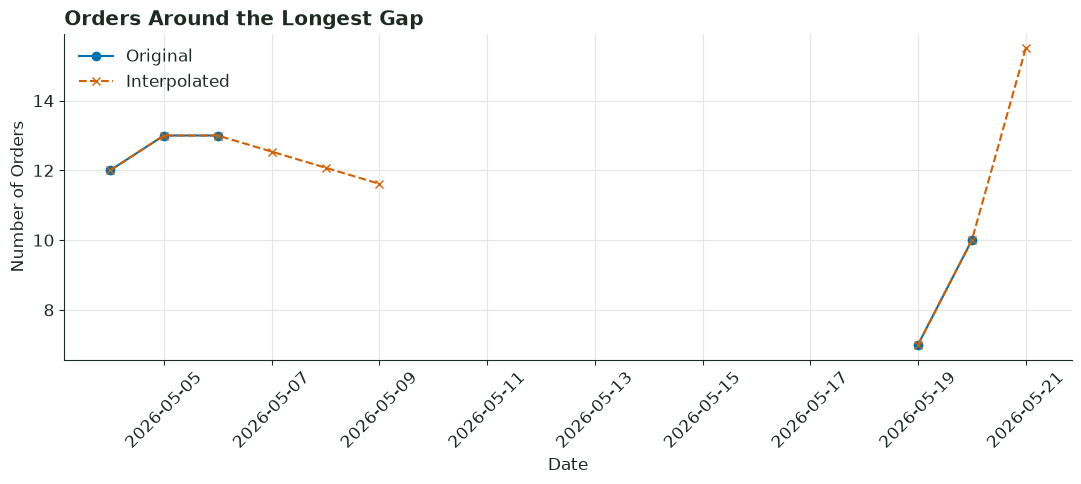

In [58]:

# Gi naogjame originalnite missing days
missing = daily[count_col].isna()

# Grupiranje na posledovatelni missing days
groups = missing.ne(missing.shift()).cumsum()

# Dolzhina na sekoja praznina
gaps = missing[missing].groupby(groups[missing]).size()

if not gaps.empty:
    # Najdolga praznina
    longest_group = gaps.idxmax()
    longest_gap = gaps.max()

    gap_dates = daily.index[
        missing & (groups == longest_group)
    ]

    gap_start = gap_dates[0]
    gap_end = gap_dates[-1]

    print("Longest gap:", longest_gap, "days")
    print("From:", gap_start.date())
    print("To:", gap_end.date())

    # Nekolku dena pred i po prazninata
    start = gap_start - pd.Timedelta(days=3)
    end = gap_end + pd.Timedelta(days=3)

    comparison = pd.DataFrame({
        "Original": daily[count_col],
        "Filled": daily_filled[count_col]
    }).loc[start:end]

    display(comparison)

    # Grafikon
    plt.figure(figsize=(11, 5))

    plt.plot(
        comparison.index,
        comparison["Original"],
        marker="o",
        label="Original"
    )

    plt.plot(
        comparison.index,
        comparison["Filled"],
        marker="x",
        linestyle="--",
        label="Interpolated"
    )

    plt.title("Orders Around the Longest Gap")
    plt.xlabel("Date")
    plt.ylabel("Number of Orders")
    plt.xticks(rotation=45)
    plt.legend()
    plt.tight_layout()
    plt.show()

else:
    print("No missing days found.")


## Task 3: Outliers

### 3.1 Unusual Numbers of Items

Flag the unusual numbers of items among the training orders in two ways: as more than 1.5 interquartile ranges beyond the quartiles, and as more than three standard deviations from the mean. Report how many orders each way flags, show them, and explain why the two ways disagree.

In [60]:

# IQR Method
items = X_train["items"]

Q1 = items.quantile(0.25)
Q3 = items.quantile(0.75)
IQR = Q3 - Q1

lower_iqr = Q1 - 1.5 * IQR
upper_iqr = Q3 + 1.5 * IQR

iqr_outliers = (items < lower_iqr) | (items > upper_iqr)

print("IQR outliers:", iqr_outliers.sum())


IQR outliers: 14


In [61]:

# Standard Deviation Method
mean_items = items.mean()
std_items = items.std()

lower_std = mean_items - 3 * std_items
upper_std = mean_items + 3 * std_items

std_outliers = (items < lower_std) | (items > upper_std)

print("STD outliers:", std_outliers.sum())


STD outliers: 4


In [62]:

# Sporedba na dvata metoda
comparison = X_train.loc[
    iqr_outliers | std_outliers,
    ["order_id", "items"]
].copy()

comparison["IQR_outlier"] = iqr_outliers
comparison["STD_outlier"] = std_outliers

print("IQR outliers:", iqr_outliers.sum())
print("STD outliers:", std_outliers.sum())

display(comparison.sort_values("items"))


IQR outliers: 14
STD outliers: 4


,order_id,items,IQR_outlier,STD_outlier
180,73181,28,True,False
22,73023,29,True,False
177,73178,30,True,False
35,73036,32,True,False
14,73015,39,True,False
286,73287,44,True,False
275,73276,48,True,False
99,73100,54,True,False
216,73217,57,True,False
85,73086,60,True,False


### 3.2 Errors or Genuine Values

Decide for each flagged number of items whether it is an error or a genuine value, and handle it accordingly in `X`, `X_train`, and `X_test`.

In [63]:
# X gi sodrzhi site podatoci osven rating
X = df.drop(columns=["rating"]).copy()

# Granici nauceni samo od X_train
items = X_train["items"]

Q1 = items.quantile(0.25)
Q3 = items.quantile(0.75)
IQR = Q3 - Q1

mean_items = items.mean()
std_items = items.std()

lower_iqr = Q1 - 1.5 * IQR
upper_iqr = Q3 + 1.5 * IQR

lower_std = mean_items - 3 * std_items
upper_std = mean_items + 3 * std_items

# Gi naogjame site neobicni naracki
flagged = (
    (X["items"] < lower_iqr) |
    (X["items"] > upper_iqr) |
    (X["items"] < lower_std) |
    (X["items"] > upper_std)
)

flagged_orders = X.loc[
    flagged,
    ["order_id", "items", "customer_type", "order_value"]
].sort_values("items")

print("Flagged orders:")
display(flagged_orders)

# Za sekoja naracka odlucuvame:
# e = error, g = genuine
error_ids = []

for _, row in flagged_orders.iterrows():
    print(
        f"\nOrder {row['order_id']}: "
        f"items={row['items']}, "
        f"type={row['customer_type']}, "
        f"value={row['order_value']}"
    )

    decision = input("Error (e) or Genuine (g)? ").strip().lower()

    while decision not in ["e", "g"]:
        decision = input("Enter e or g: ").strip().lower()

    if decision == "e":
        error_ids.append(row["order_id"])

# Zamena na greskite so median od ispravni training orders
valid_train = X_train.loc[
    ~X_train["order_id"].isin(error_ids), "items"
]

items_median = int(round(valid_train.median()))

# Gi primenuvame istite odluki vo site mnozestva
for data in [X, X_train, X_test]:
    error_mask = data["order_id"].isin(error_ids)

    data["items_error"] = error_mask.astype(int)
    data.loc[error_mask, "items"] = items_median

# Rezultati
print("\nOrders classified as errors:", len(error_ids))
print("Replacement value:", items_median)

print("\nCorrected orders:")
display(
    X.loc[X["items_error"] == 1,
          ["order_id", "items", "items_error"]]
)

print("\nX shape:", X.shape)
print("X_train shape:", X_train.shape)
print("X_test shape:", X_test.shape)


Flagged orders:


,order_id,items,customer_type,order_value
180,73181,28,business,1152.71
22,73023,29,business,708.53
326,73327,29,business,305.14
177,73178,30,business,908.52
35,73036,32,business,385.21
378,73379,36,business,970.16
14,73015,39,business,675.78
353,73354,42,business,1234.79
286,73287,44,business,511.24
275,73276,48,business,1271.68



Order 73181: items=28, type=business, value=1152.71


Error (e) or Genuine (g)?  e



Order 73023: items=29, type=business, value=708.53


Error (e) or Genuine (g)?  g


... (31 outputs left out)

Error (e) or Genuine (g)?  e



Orders classified as errors: 13
Replacement value: 2

Corrected orders:


,order_id,items,items_error
85,73086,2,1
89,73090,2,1
99,73100,2,1
172,73173,2,1
173,73174,2,1
177,73178,2,1
180,73181,2,1
216,73217,2,1
275,73276,2,1
278,73279,2,1



X shape: (392, 16)
X_train shape: (294, 18)
X_test shape: (98, 18)


### 3.3 Unusual Combinations

Among the training orders of consumers with a known number of items and a known package weight, find the orders whose combination of items and weight is unusual, in two ways: by how quickly random splits isolate an order, and by how much sparser its neighbourhood is than the neighbourhoods of its neighbours. Judge both on the two columns standardized, treat 2% of the orders as unusual, use 20 neighbours, and use the seed 2026. Decide what to do with the orders that both ways flag.

Total consumer orders: 228
Isolation Forest outliers: 5
LOF outliers: 5
Flagged by both: 2

All flagged orders:


,order_id,items,package_weight,IsolationForest,LOF,Both
131,73132,1,6.9,True,True,True
190,73191,1,6.2,True,True,True
1,73002,6,6.0,True,False,False
29,73030,6,4.7,True,False,False
51,73052,6,5.9,True,False,False
68,73069,1,2.0,False,True,False
128,73129,1,6.6,False,True,False
270,73271,1,6.7,False,True,False



Orders flagged by BOTH methods:


,order_id,items,package_weight,order_value,customer_type
131,73132,1,6.9,25.29,consumer
190,73191,1,6.2,24.44,consumer


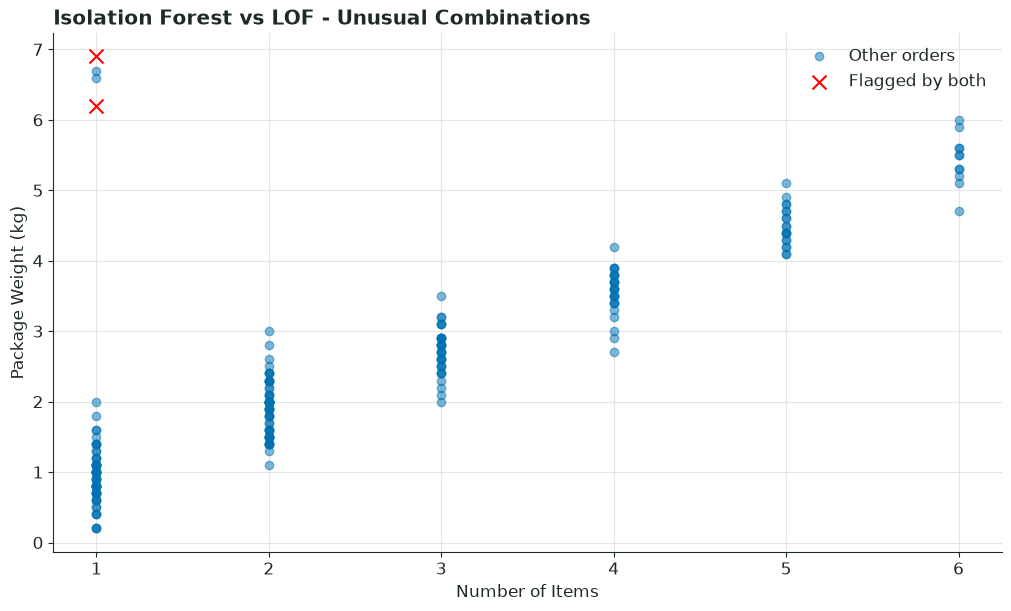


Decision:
Keep orders flagged by both methods.
Unusual combinations are not necessarily data errors.
No rows are deleted or modified.


In [64]:

from sklearn.ensemble import IsolationForest
from sklearn.neighbors import LocalOutlierFactor
from sklearn.preprocessing import StandardScaler
import matplotlib.pyplot as plt

# Samo consumer naracki so originalno poznati items i package_weight
known_mask = (
    (X_train["customer_type"] == "consumer") &
    train["items"].notna() &
    train["package_weight"].notna()
)

consumer_orders = X_train.loc[known_mask].copy()

# Dvete numericki koloni
features = consumer_orders[["items", "package_weight"]]

# Standardizacija
scaler = StandardScaler()
features_scaled = scaler.fit_transform(features)

# 1. Isolation Forest
iso = IsolationForest(
    contamination=0.02,
    random_state=2026
)

consumer_orders["IsolationForest"] = (
    iso.fit_predict(features_scaled) == -1
)

# 2. Local Outlier Factor (20 neighbours)
lof = LocalOutlierFactor(
    n_neighbors=20,
    contamination=0.02
)

consumer_orders["LOF"] = (
    lof.fit_predict(features_scaled) == -1
)

# Naracki oznaceni od dvata metoda
consumer_orders["Both"] = (
    consumer_orders["IsolationForest"] &
    consumer_orders["LOF"]
)

# Rezultati
print("Total consumer orders:", len(consumer_orders))
print("Isolation Forest outliers:",
      consumer_orders["IsolationForest"].sum())
print("LOF outliers:",
      consumer_orders["LOF"].sum())
print("Flagged by both:",
      consumer_orders["Both"].sum())

# Prikaz na site oznaceni naracki
print("\nAll flagged orders:")
display(
    consumer_orders.loc[
        consumer_orders["IsolationForest"] |
        consumer_orders["LOF"],
        ["order_id", "items", "package_weight",
         "IsolationForest", "LOF", "Both"]
    ].sort_values(["Both", "items"], ascending=[False, False])
)

# Prikaz na narackite oznaceni od dvata metoda
both_flagged = consumer_orders.loc[
    consumer_orders["Both"]
].copy()

print("\nOrders flagged by BOTH methods:")
display(
    both_flagged[
        ["order_id", "items", "package_weight",
         "order_value", "customer_type"]
    ]
)

# Vizuelizacija
plt.figure(figsize=(10, 6))

normal = consumer_orders[~consumer_orders["Both"]]

plt.scatter(
    normal["items"],
    normal["package_weight"],
    alpha=0.5,
    label="Other orders"
)

plt.scatter(
    both_flagged["items"],
    both_flagged["package_weight"],
    color="red",
    marker="x",
    s=100,
    label="Flagged by both"
)

plt.xlabel("Number of Items")
plt.ylabel("Package Weight (kg)")
plt.title("Isolation Forest vs LOF - Unusual Combinations")
plt.legend()
plt.show()

# Decision: Keep unusual orders unless there is evidence of an error
print("\nDecision:")
print("Keep orders flagged by both methods.")
print("Unusual combinations are not necessarily data errors.")
print("No rows are deleted or modified.")


### 3.4 Capping the Delivery Days

Find the 1st and the 99th percentiles of the delivery days among the training orders, and count the test orders that lie beyond them. Decide whether to cap the delivery days at these bounds.

1st percentile: 1.0
99th percentile: 5.0

Test orders below 1st percentile: 0
Test orders above 99th percentile: 7
Total test orders outside bounds: 7

Test orders outside the bounds:


,order_id,delivery_days
358,73359,8.0
341,73342,9.0
389,73390,9.0
343,73344,10.0
369,73370,11.0
321,73322,12.0
342,73343,12.0


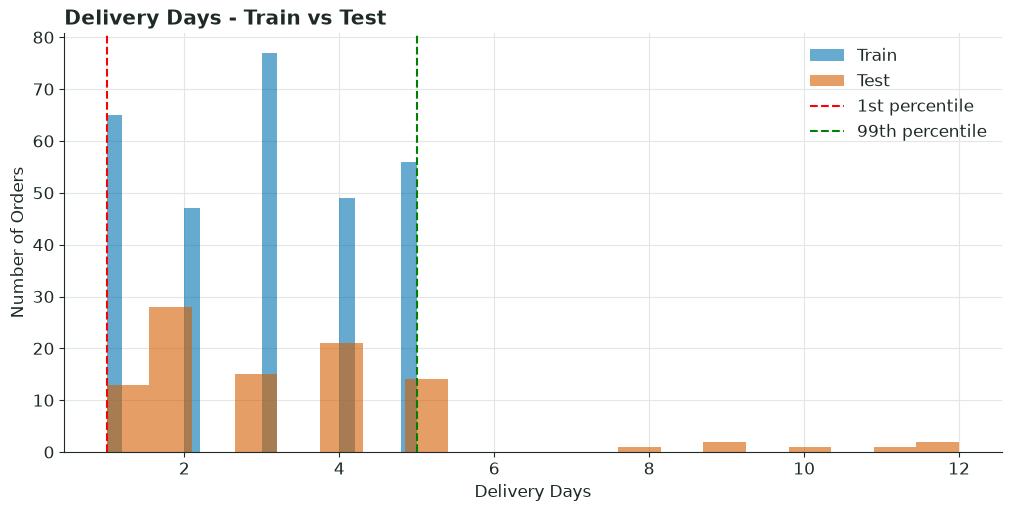


Decision: No capping applied.
Unusual delivery times may represent genuine delays.


In [65]:

# Task 3.4 - Capping the Delivery Days

# 1st and 99th percentiles from training data only
lower_bound = X_train["delivery_days"].quantile(0.01)
upper_bound = X_train["delivery_days"].quantile(0.99)

print("1st percentile:", lower_bound)
print("99th percentile:", upper_bound)

# Test orders outside the bounds
below = X_test["delivery_days"] < lower_bound
above = X_test["delivery_days"] > upper_bound

print("\nTest orders below 1st percentile:", below.sum())
print("Test orders above 99th percentile:", above.sum())
print("Total test orders outside bounds:", (below | above).sum())

# Show unusual test orders
print("\nTest orders outside the bounds:")
display(
    X_test.loc[
        below | above,
        ["order_id", "delivery_days"]
    ].sort_values("delivery_days")
)

# Compare training and test distributions
plt.figure(figsize=(10, 5))

plt.hist(X_train["delivery_days"], bins=20, alpha=0.6, label="Train")
plt.hist(X_test["delivery_days"], bins=20, alpha=0.6, label="Test")

plt.axvline(lower_bound, color="red", linestyle="--", label="1st percentile")
plt.axvline(upper_bound, color="green", linestyle="--", label="99th percentile")

plt.xlabel("Delivery Days")
plt.ylabel("Number of Orders")
plt.title("Delivery Days - Train vs Test")
plt.legend()
plt.show()

# Decision:
# Do not cap automatically because long deliveries may be genuine.
# Keep the original delivery_days values.

print("\nDecision: No capping applied.")
print("Unusual delivery times may represent genuine delays.")


## Task 4: Encoding and Scaling

### 4.1 Labels as Numbers

Turn every label into numbers in the way its kind calls for, learning from the training orders:

- the membership keeps its order, from none to platinum,
- a label without an order gets one column per category, a single column when it has two categories, and zeros for a category that the training orders never held, and
- the city becomes its share of the training orders, with 0 for a city that the training orders never held.

Report the code of each membership level, the number of columns that the labels without an order become, and the share of Kumanovo.

In [ ]:
# Write your solution here.

### 4.2 Comparable Scales

Bring every numeric column to a scale that suits it, and reduce the skew of the columns with a long right tail. Report the skew of the account age before and after, the power that brings it closest to a normal distribution, and what the discount needs instead.

In [ ]:
# Write your solution here.

## Task 5: One Pipeline and Leakage

### 5.1 One Preparation

Join every step of Tasks 2 to 4 into one preparation that is fitted on the training orders and only applied to the test orders. Report the number of rows and columns of the prepared training and test tables, and confirm that they hold no missing values.

In [ ]:
# Write your solution here.

### 5.2 Fitted on All Orders

Fit the same preparation on all orders, the test orders included, and compare what it learns for the cities that only the test orders hold with what the preparation fitted on the training orders learns. Then show how the leak changes the test orders on the delivery days. Standardize the known test delivery days once with the mean and the standard deviation of the training orders and once with those of all orders, compare how far they spread, and count the test orders beyond the 99th percentile of the delivery days of the training orders and of all orders.

In [ ]:
# Write your solution here.

### 5.3 The Decisions

Record every preparation decision in a table, with the reason the data give for it.